# **Sentiment Analysis on Amazon Reviews**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\vishn\innomatics\Machine_Learning\Reviews.csv\Reviews.csv")
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


In [4]:
df.isnull().sum()/len(df)*100

Id                        0.000000
ProductId                 0.000000
UserId                    0.000000
ProfileName               0.004574
HelpfulnessNumerator      0.000000
HelpfulnessDenominator    0.000000
Score                     0.000000
Time                      0.000000
Summary                   0.004750
Text                      0.000000
dtype: float64

In [5]:
df=df.dropna(subset=["ProfileName","Summary"])
print(df.shape)
df.isnull().sum()/len(df)*100

(568401, 10)


Id                        0.0
ProductId                 0.0
UserId                    0.0
ProfileName               0.0
HelpfulnessNumerator      0.0
HelpfulnessDenominator    0.0
Score                     0.0
Time                      0.0
Summary                   0.0
Text                      0.0
dtype: float64

In [6]:
df.columns

Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='str')

In [7]:
cols=['ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator','HelpfulnessDenominator', 'Score','Time', 'Summary', 'Text']

df.duplicated(subset=cols).sum()

np.int64(281)

In [8]:
print("Before:", df.shape)

df = df.drop_duplicates(subset=cols)

print("After:", df.shape)
df.duplicated(subset=cols).sum()

Before: (568401, 10)
After: (568120, 10)


np.int64(0)

In [9]:
print(df["Score"].value_counts().sort_index())
print()
print((df["Score"].value_counts().sort_index()/len(df)*100).round(2))

Score
1     52227
2     29739
3     42612
4     80626
5    362916
Name: count, dtype: int64

Score
1     9.19
2     5.23
3     7.50
4    14.19
5    63.88
Name: count, dtype: float64


## **Text Preprocessing**

In [10]:
df["clean_text"]=(df["Text"]
                  .str.lower()  #lowercase
                  .str.replace(r"<.*?"," ",regex=True) # remove HTML tags
                  .str.replace(r"http\s+|www\.\S+"," ",regex=True) #remove URLs
                  .str.replace(r"[^a-z\s]"," ",regex=True)  #remove punctuation (and digits)
                  .str.replace(r"\s+"," ",regex=True)  #remove extra spaces
                  .str.strip()  #remove strips both ends
                  )

df[["Text","clean_text"]].head()

,Text,clean_text
0,I have bought several of the Vitality canned d...,i have bought several of the vitality canned d...
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled as jumbo salted peanut...
2,This is a confection that has been around a fe...,this is a confection that has been around a fe...
3,If you are looking for the secret ingredient i...,if you are looking for the secret ingredient i...
4,Great taffy at a great price. There was a wid...,great taffy at a great price there was a wide ...


## **Tokenization**

In [11]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")

df["tokens"]=df["clean_text"].apply(word_tokenize)
df[["clean_text","tokens"]].head()

[nltk_data] Error loading punkt: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading punkt_tab: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


,clean_text,tokens
0,i have bought several of the vitality canned d...,"[i, have, bought, several, of, the, vitality, ..."
1,product arrived labeled as jumbo salted peanut...,"[product, arrived, labeled, as, jumbo, salted,..."
2,this is a confection that has been around a fe...,"[this, is, a, confection, that, has, been, aro..."
3,if you are looking for the secret ingredient i...,"[if, you, are, looking, for, the, secret, ingr..."
4,great taffy at a great price there was a wide ...,"[great, taffy, at, a, great, price, there, was..."


## **Remove stopwords and lemmatize**

In [12]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Error loading stopwords: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading wordnet: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading omw-1.4: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


False

In [13]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words=set(stopwords.words("english"))
lemmatizer=WordNetLemmatizer()

df["tokens"]=df["tokens"].apply(
    lambda words:[lemmatizer.lemmatize(w) for w in words if w not in stop_words]
)

#join back to a string for vectorization later
df["clean_text"]=df["tokens"].apply(lambda words: " ".join(words))

df[["Text","tokens","clean_text"]].head()

,Text,tokens,clean_text
0,I have bought several of the Vitality canned d...,"[bought, several, vitality, canned, dog, food,...",bought several vitality canned dog food produc...
1,Product arrived labeled as Jumbo Salted Peanut...,"[product, arrived, labeled, jumbo, salted, pea...",product arrived labeled jumbo salted peanut pe...
2,This is a confection that has been around a fe...,"[confection, around, century, light, pillowy, ...",confection around century light pillowy citrus...
3,If you are looking for the secret ingredient i...,"[looking, secret, ingredient, robitussin, beli...",looking secret ingredient robitussin believe f...
4,Great taffy at a great price. There was a wid...,"[great, taffy, great, price, wide, assortment,...",great taffy great price wide assortment yummy ...


## **EDA**

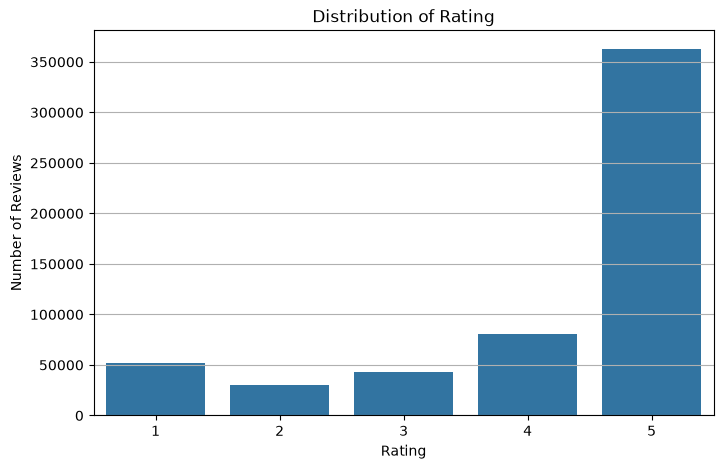

In [14]:
from matplotlib.lines import lineStyles
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(x="Score",data=df, order=[1,2,3,4,5])
plt.title("Distribution of Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.grid(axis="y")
plt.show()

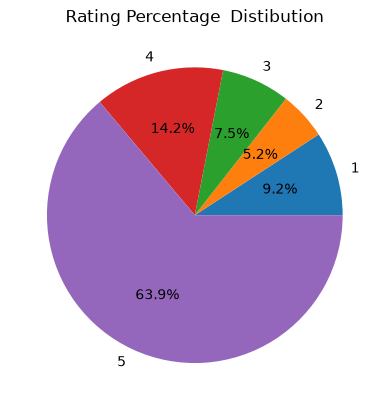

In [15]:
rating_pct=df["Score"].value_counts().sort_index()

plt.pie(rating_pct, labels=rating_pct.index, autopct="%1.1f%%")
plt.title("Rating Percentage  Distibution")
plt.show()

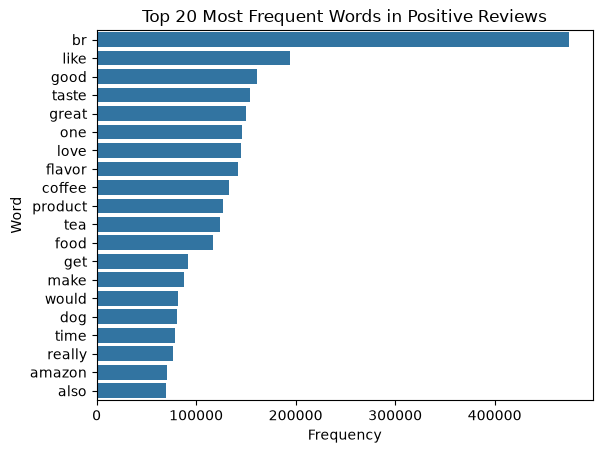

In [16]:
# most frequent words in positive reviews

positive_words=df[df["Score"]>=4]["tokens"].explode().value_counts().head(20)

sns.barplot(x=positive_words,y=positive_words.index)
plt.title("Top 20 Most Frequent Words in Positive Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

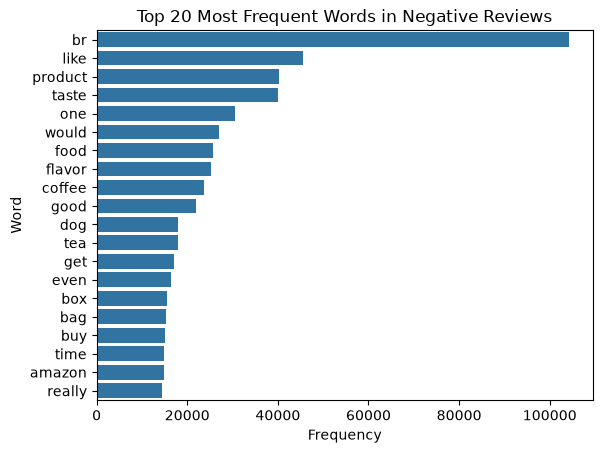

In [17]:
# most frequent words in Negative reviews

Negative_words=df[df["Score"]<=2]["tokens"].explode().value_counts().head(20)

sns.barplot(x=Negative_words,y=Negative_words.index)
plt.title("Top 20 Most Frequent Words in Negative Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

In [18]:
! pip install wordcloud


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


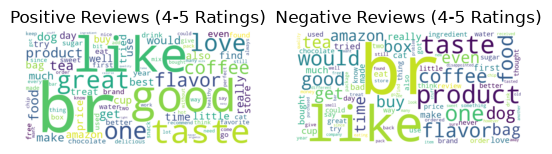

In [19]:
# word clouds for positive and negative reviews

import matplotlib.pyplot as plt

from wordcloud import WordCloud

pos_freq=df[df["Score"]>=4]["tokens"].explode().value_counts().head(100).to_dict()
neg_freq=df[df["Score"]<=2]["tokens"].explode().value_counts().head(100).to_dict()

pos_cloud=WordCloud(width=800,height=400,background_color="white").generate_from_frequencies(pos_freq)
neg_cloud=WordCloud(width=800,height=400,background_color="white").generate_from_frequencies(neg_freq)

plt.subplot(1,2,1)
plt.imshow(pos_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Reviews (4-5 Ratings)")

plt.subplot(1,2,2)
plt.imshow(neg_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Reviews (4-5 Ratings)")

plt.show()

Reviews with votes: 298292


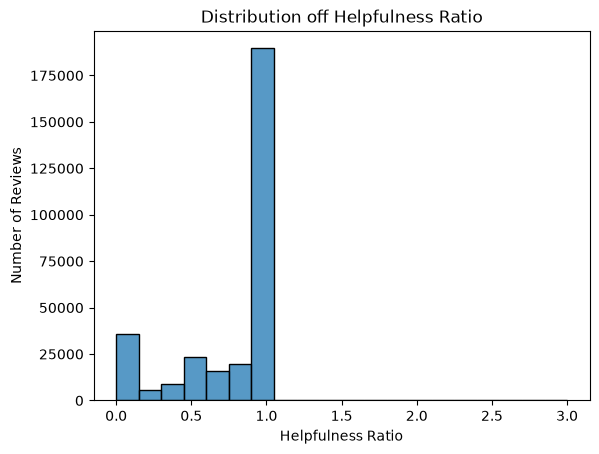

In [20]:
#Distribution of Helpfulnes Ratio
df["HelpfulnessRatio"]=df["HelpfulnessNumerator"]/df["HelpfulnessDenominator"]

voted=df[df["HelpfulnessDenominator"]>0]
print("Reviews with votes:", len(voted))

sns.histplot(voted["HelpfulnessRatio"], bins=20)
plt.title("Distribution off Helpfulness Ratio")
plt.xlabel("Helpfulness Ratio")
plt.ylabel("Number of Reviews")
plt.show()

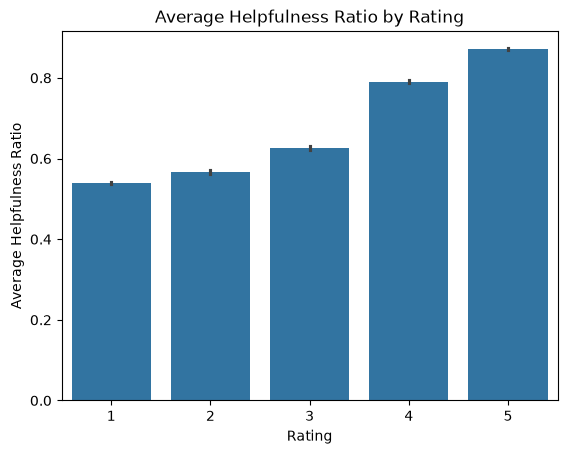

In [21]:
# Rekationship between Rating and Helpfulness

sns.barplot(data=voted,x="Score",y="HelpfulnessRatio", order=[1,2,3,4,5])
plt.title("Average Helpfulness Ratio by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Helpfulness Ratio")
plt.show()

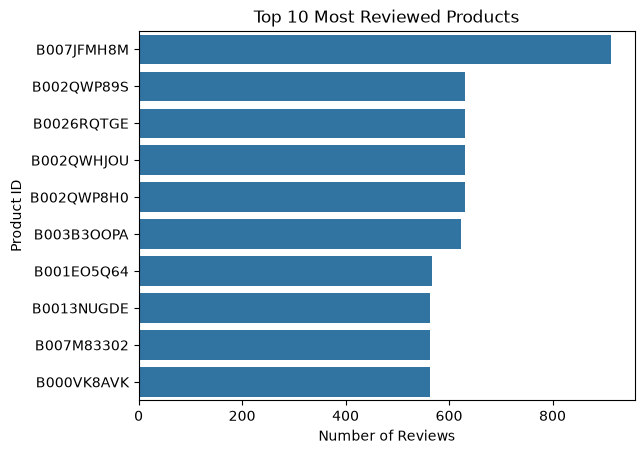

In [22]:
#Top Reviewed Products

top_products=df["ProductId"].value_counts().head(10)

sns.barplot(x=top_products.values, y=top_products.index)
plt.title("Top 10 Most Reviewed Products")
plt.xlabel("Number of Reviews")
plt.ylabel("Product ID")
plt.show()

# **Machine Learning Model Development**

In [23]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,clean_text,tokens,HelpfulnessRatio
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...,bought several vitality canned dog food produc...,"[bought, several, vitality, canned, dog, food,...",1.0
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled jumbo salted peanut pe...,"[product, arrived, labeled, jumbo, salted, pea...",NaN
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...,confection around century light pillowy citrus...,"[confection, around, century, light, pillowy, ...",1.0
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...,looking secret ingredient robitussin believe f...,"[looking, secret, ingredient, robitussin, beli...",1.0
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...,great taffy great price wide assortment yummy ...,"[great, taffy, great, price, wide, assortment,...",NaN


In [24]:
import pandas as pd

#Feature selection: keep only the text and the target
df=df[["clean_text","Score"]]

#some reviews may be empty after cleaning
print(df.isnull().sum())
df=df.dropna(subset=["clean_text"])

print(df.shape)
df.head()

clean_text    0
Score         0
dtype: int64
(568120, 2)


,clean_text,Score
0,bought several vitality canned dog food produc...,5
1,product arrived labeled jumbo salted peanut pe...,1
2,confection around century light pillowy citrus...,4
3,looking secret ingredient robitussin believe f...,2
4,great taffy great price wide assortment yummy ...,5


In [25]:
y=df["Score"]
X=df["clean_text"]

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print(X_train.shape)
print(X_test.shape)

(454496,)
(113624,)


In [26]:
#Vectorization (Bag of Words and TF-IDF)

from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer

#Bag of Words
bow=CountVectorizer()
X_train_bow=bow.fit_transform(X_train)
X_test_bow=bow.transform(X_test)

#TF-IDF
tfidf=TfidfVectorizer()
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)

print("BoW:", X_train_bow.shape, X_test_bow.shape)
print("TF-IDF:",X_train_tfidf.shape,X_test_tfidf.shape)

BoW: (454496, 89454) (113624, 89454)
TF-IDF: (454496, 89454) (113624, 89454)


## **Linear SVC**

In [27]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

linear_svc=LinearSVC(penalty="l2",
                     loss="squared_hinge",
                     C= 1.0,
                     multi_class="ovr",
                     class_weight="balanced",
                     random_state=42,
                     dual=False)
linear_svc.fit(X_train_tfidf,y_train)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo

In [28]:
y_pred=linear_svc.predict(X_test_tfidf)
accuracy_score(y_test,y_pred)

0.73549602196719

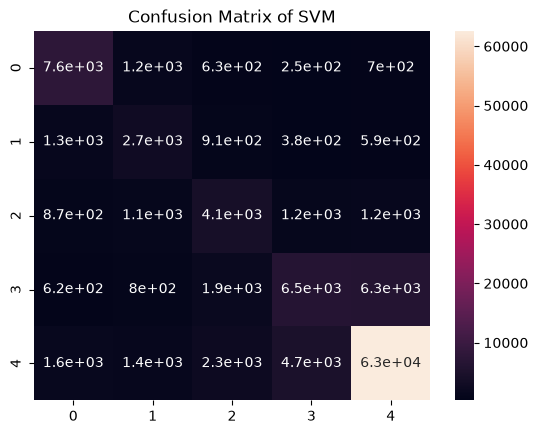

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix,classification_report
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True)
plt.title("Confusion Matrix of SVM")
plt.show()

In [30]:
cr=classification_report(y_test,y_pred)
print(cr)

              precision    recall  f1-score   support

           1       0.63      0.73      0.68     10446
           2       0.38      0.46      0.41      5948
           3       0.42      0.48      0.45      8522
           4       0.50      0.40      0.45     16125
           5       0.88      0.86      0.87     72583

    accuracy                           0.74    113624
   macro avg       0.56      0.59      0.57    113624
weighted avg       0.74      0.74      0.74    113624



# **Make Prediction**

In [71]:
input_data=df["clean_text"][8777]

new_row_df=pd.DataFrame({"review_text":[input_data]})

#extract the text stringusing correct column name
text_to_predict=new_row_df["review_text"]

input_sparse=tfidf.transform(text_to_predict)

prediction=linear_svc.predict(input_sparse)

print(f"predicted score: {prediction} out of 5")

if prediction>=4:
    print("Sentiment: Positive Aspect")
elif prediction==3:
    print("Sentiment: Neutral Aspect")
else:
    print("Sentiment: Negative Aspect")

predicted score: [4] out of 5
Sentiment: Positive Aspect


In [56]:
df["Score"].value_counts()

Score
5    362916
4     80626
1     52227
3     42612
2     29739
Name: count, dtype: int64

# **Saving The Trained Model**

In [58]:
import pickle

In [59]:
filename="sentiment_review_trained_model.sav"
pickle.dump(linear_svc,open(filename,"wb"))

In [62]:
#loading the saved model(change back slash to forward slash)
sentiment_review_loaded_model=pickle.load(open("C:/Users/vishn/innomatics/Machine_Learning/Amazon_Review_project/sentiment_review_trained_model.sav","rb"))

In [79]:
filename="sentiment_tfidf_trained"
pickle.dump(tfidf,open(filename,"wb"))

In [80]:
sentiment_tfidf_loaded=pickle.load(open("C:/Users/vishn/innomatics/Machine_Learning/Amazon_Review_project/sentiment_tfidf_trained","rb"))

In [81]:
input_data=df["clean_text"][8777]

new_row_df=pd.DataFrame({"review_text":[input_data]})

#extract the text stringusing correct column name
text_to_predict=new_row_df["review_text"]

input_sparse=sentiment_tfidf_loaded.transform(text_to_predict)

prediction=sentiment_review_loaded_model.predict(input_sparse)

print(f"predicted score: {prediction} out of 5")

if prediction>=4:
    print("Sentiment: Positive Aspect")
elif prediction==3:
    print("Sentiment: Neutral Aspect")
else:
    print("Sentiment: Negative Aspect")

predicted score: [4] out of 5
Sentiment: Positive Aspect


In [84]:
df

,clean_text,Score
0,bought several vitality canned dog food produc...,5
1,product arrived labeled jumbo salted peanut pe...,1
2,confection around century light pillowy citrus...,4
3,looking secret ingredient robitussin believe f...,2
4,great taffy great price wide assortment yummy ...,5
...,...,...
568449,great sesame chicken good better resturants ea...,5
568450,disappointed flavor chocolate note especially ...,2
568451,star small give one training session tried tra...,5
568452,best treat training rewarding dog good groomin...,5
